# 08 · Conclusions

**Question:** with every model scored on the same 25 grouped splits, what can honestly be claimed about
recognising a baby's state from its cry with this dataset?

This notebook trains nothing. It reads the saved out-of-fold predictions of notebooks 04 (baselines),
05 (10 classical variants) and 07 (2 CNN variants, run on a Colab T4), and scores them all the same way:
1. one comparison table, with cluster-bootstrap intervals and paired differences;
2. per-class results with reliability flags, and the ranking signal per class;
3. the recording-format check for the best classical model and both CNNs;
4. the CNN training curves;
5. a sensitivity check without the most inconsistent source (d6cda191, notebook 06);
6. what can be claimed, limitations, and a short model card.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from src import viz
from src.audio import CLASSES, load_clean_index
from src.metrics import (balanced_accuracy, cluster_bootstrap, encode, interval, macro_f1, paired_bootstrap,
                         per_class_table, predictions_by_repeat, repeat_scores)
from src.splits import PROBA_COLS, load_predictions

viz.set_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 60)
idx = load_clean_index()
t, groups = encode(idx["label"]), idx["source"].to_numpy()
RESULTS = REPO / "results"

# (family, model, variant, predictions file); the menu was fixed in the project plan
MODELS = [("baseline", "majority", "-", "majority"), ("baseline", "prior_random", "-", "prior_random")]
for m in ["logistic_regression", "knn", "svm_rbf", "random_forest", "hist_gradient_boosting"]:
    for v in ["argmax", "prior_corrected"]:
        MODELS.append(("classical", m, v, f"ml_{m}_{v}"))
MODELS += [("cnn", "cnn", v, f"cnn_{v}") for v in ["weighted_loss", "balanced_sampler"]]
pred = {f: load_predictions(f, idx) for *_, f in MODELS}
for f, p in pred.items():
    assert len(p) == 5 * len(idx) and (p.groupby("repeat")["clip"].nunique() == len(idx)).all(), f
print(f"{len(MODELS)} models x 5 repeats x {len(idx)} clips, every clip predicted once per repeat")

14 models x 5 repeats x 479 clips, every clip predicted once per repeat


## 1. Every model on one table

Means over the 5 repeats (± std). 95% intervals: cluster bootstrap over babies (1000 draws). "vs majority" is
the paired bootstrap difference in balanced accuracy from always answering *hungry*. "vs RF" compares
with the best classical model, random forest (argmax), on the same resampled babies. Nothing was re-tuned here.

With 12 models compared to the baseline, about one interval in twenty could exclude 0 by chance
even with no real effect. A single narrow miss would not be evidence.

In [2]:
majority = predictions_by_repeat(pred["majority"], len(idx))
rf = predictions_by_repeat(pred["ml_random_forest_argmax"], len(idx))


def score(p, mask=None, n_boot=1000):
    preds = predictions_by_repeat(p, len(idx))
    keep = np.ones(len(idx), bool) if mask is None else mask
    sub = p[keep[p["clip"].to_numpy()]]
    per_rep = repeat_scores(sub)
    tt, gg = t[keep], groups[keep]
    pp, mm, rr = [q[keep] for q in preds], [q[keep] for q in majority], [q[keep] for q in rf]
    row = {m: per_rep[m].mean() for m in per_rep.columns}
    row["ba_std"] = per_rep["balanced_accuracy"].std(ddof=1)
    row["ba_low"], row["ba_high"] = interval(cluster_bootstrap(tt, pp, gg, balanced_accuracy, n_boot, seed=0))
    row["f1_low"], row["f1_high"] = interval(cluster_bootstrap(tt, pp, gg, macro_f1, n_boot, seed=0))
    d = paired_bootstrap(tt, pp, mm, gg, n_boot=n_boot, seed=0)
    row["vs_majority"], (row["vs_majority_low"], row["vs_majority_high"]) = d.mean(), interval(d)
    d = paired_bootstrap(tt, pp, rr, gg, n_boot=n_boot, seed=0)
    row["vs_rf"], (row["vs_rf_low"], row["vs_rf_high"]) = d.mean(), interval(d)
    return row


table = pd.DataFrame([{"family": fam, "model": m, "variant": v, **score(pred[f])} for fam, m, v, f in MODELS])
table.to_csv(RESULTS / "final_scores.csv", index=False, float_format="%.6g")
f3, ci = "{:.3f}".format, lambda lo, hi: lo.map("{:+.3f}".format) + ", " + hi.map("{:+.3f}".format)
pd.DataFrame({
    "balanced acc": table["balanced_accuracy"].map(f3) + " ± " + table["ba_std"].map(f3),
    "BA 95% CI": table["ba_low"].map(f3) + "-" + table["ba_high"].map(f3),
    "macro-F1 (95% CI)": table["macro_f1"].map(f3) + " (" + table["f1_low"].map(f3) + "-" + table["f1_high"].map(f3) + ")",
    "vs majority": table["vs_majority"].map("{:+.3f}".format) + " (" + ci(table["vs_majority_low"], table["vs_majority_high"]) + ")",
    "vs RF": table["vs_rf"].map("{:+.3f}".format) + " (" + ci(table["vs_rf_low"], table["vs_rf_high"]) + ")",
    "MCC": table["mcc"].map(f3), "log-loss": table["log_loss"].map(f3), "top-3": table["top3_accuracy"].map(f3),
}).set_index(pd.MultiIndex.from_frame(table[["family", "model", "variant"]]))

balanced acc    BA 95% CI    macro-F1 (95% CI)              vs majority                    vs RF     MCC log-loss  \
family    model                  variant                                                                                                                                
baseline  majority               -                 0.125 ± 0.000  0.125-0.143  0.111 (0.106-0.130)  +0.000 (+0.000, +0.000)  -0.006 (-0.016, +0.002)   0.000    0.887   
          prior_random           -                 0.132 ± 0.007  0.119-0.151  0.132 (0.118-0.150)  +0.006 (-0.007, +0.022)  +0.000 (-0.019, +0.020)   0.019    0.887   
classical logistic_regression    argmax            0.125 ± 0.007  0.109-0.160  0.124 (0.106-0.150)  +0.002 (-0.017, +0.026)  -0.004 (-0.023, +0.020)   0.000    1.542   
                                 prior_corrected   0.103 ± 0.017  0.084-0.137  0.098 (0.086-0.117)  -0.021 (-0.042, +0.006)  -0.027 (-0.048, -0.000)   0.005    1.635   
          knn                    argmax            0.126 ± 0.003  0.122-0.145  0.115 (0.107-0.136)  +0.001 (-0.003, +0.006)  -0.005 (-0.014, +0.002)   0.003    4.883   
                                 prior_corrected   0.108 ± 0.012  0.092-0.139  0.109 (0.096-0.129)  -0.017 (-0.034, +0.008)  -0.023 (-0.042, +0.001)   0.014    4.517   
          svm_rbf                argmax            0.125 ± 0.000  0.124-0.143  0.111 (0.106-0.130)  -0.000 (-0.001, +0.000)  -0.006 (-0.016, +0.002)  -0.009    0.891   
                                 prior_corrected   0.128 ± 0.006  0.115-0.153  0.126 (0.111-0.151)  +0.003 (-0.010, +0.022)  -0.003 (-0.013, +0.011)   0.030    0.907   
          random_forest          argmax            0.131 ± 0.005  0.123-0.152  0.125 (0.110-0.148)  +0.006 (-0.002, +0.016)  +0.000 (+0.000, +0.000)   0.061    1.213   
                                 prior_corrected   0.112 ± 0.023  0.084-0.145  0.094 (0.076-0.112)  -0.014 (-0.042, +0.018)  -0.020 (-0.048, +0.010)   0.009    1.267   
          hist_gradient_boosting argmax            0.126 ± 0.002  0.123-0.144  0.114 (0.107-0.134)  +0.001 (-0.002, +0.005)  -0.005 (-0.015, +0.003)   0.008    1.619   
                                 prior_corrected   0.116 ± 0.010  0.106-0.138  0.116 (0.104-0.137)  -0.009 (-0.019, +0.005)  -0.015 (-0.028, -0.001)   0.005    1.435   
cnn       cnn                    weighted_loss     0.150 ± 0.013  0.113-0.206  0.115 (0.098-0.138)  +0.026 (-0.012, +0.073)  +0.020 (-0.020, +0.065)   0.013    1.715   
                                 balanced_sampler  0.136 ± 0.030  0.099-0.177  0.054 (0.041-0.067)  +0.010 (-0.026, +0.047)  +0.004 (-0.033, +0.043)   0.004    2.230   

                                                   top-3  
family    model                  variant                  
baseline  majority               -                 0.900  
          prior_random           -                 0.900  
classical logistic_regression    argmax            0.843  
                                 prior_corrected   0.782  
          knn                    argmax            0.866  
                                 prior_corrected   0.865  
          svm_rbf                argmax            0.894  
                                 prior_corrected   0.886  
          random_forest          argmax            0.871  
                                 prior_corrected   0.875  
          hist_gradient_boosting argmax            0.879  
                                 prior_corrected   0.875  
cnn       cnn                    weighted_loss     0.831  
                                 balanced_sampler  0.425

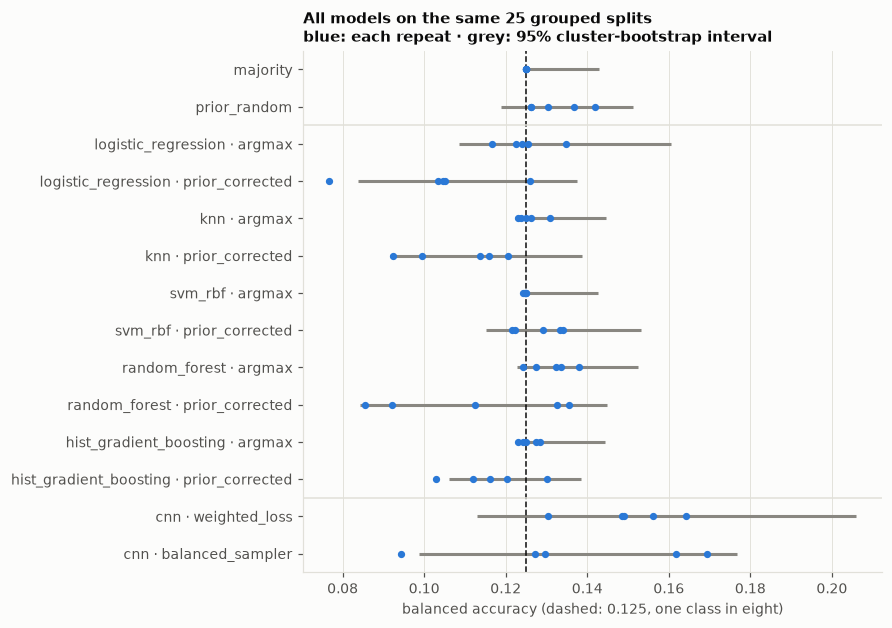

In [3]:
fig, ax = plt.subplots(figsize=(8, 5.6), constrained_layout=True)
labels = [f"{m} · {v}" if v != "-" else m for m, v in zip(table["model"], table["variant"])]
for i, ((fam, m, v, f), r) in enumerate(zip(MODELS, table.itertuples())):
    ax.plot([r.ba_low, r.ba_high], [i, i], color=viz.GREY, lw=2, solid_capstyle="butt")
    ax.scatter(repeat_scores(pred[f])["balanced_accuracy"], np.full(5, i), color=viz.BLUE, s=14, zorder=3)
ax.axvline(0.125, color=viz.INK, lw=1, ls="--")
for y in [1.5, 11.5]:
    ax.axhline(y, color=viz.GRID, lw=1)
ax.set_yticks(range(len(labels)), labels)
ax.set_ylim(len(labels) - 0.5, -0.5)
ax.grid(axis="y", visible=False)
ax.set(xlabel="balanced accuracy (dashed: 0.125, one class in eight)",
       title="All models on the same 25 grouped splits\nblue: each repeat · grey: 95% cluster-bootstrap interval")
plt.show()

## 2. Per class

Recall per class (mean over repeats) for the best classical model and both CNNs, next to the number of babies
behind each class. Classes with fewer than 5 babies cannot be estimated reliably by any model. One-vs-rest AUROC
asks whether a model at least *ranks* a class's clips above the others (0.5 = no ranking signal).

In [4]:
show = {"RF (argmax)": "ml_random_forest_argmax", "CNN weighted loss": "cnn_weighted_loss",
        "CNN balanced sampler": "cnn_balanced_sampler"}
babies = idx.groupby("label")["source"].nunique()
recall, auc = {}, {}
for name, f in show.items():
    tables = [per_class_table(encode(g.sort_values("clip")["y_true"]), encode(g.sort_values("clip")["y_pred"]), groups)
              for _, g in pred[f].groupby("repeat")]
    recall[name] = pd.concat([tb["recall"] for tb in tables], axis=1).mean(axis=1)
    auc[name] = pd.Series({c: np.mean([roc_auc_score(g["y_true"] == c, g[f"p_{c}"]) for _, g in pred[f].groupby("repeat")])
                           for c in CLASSES})
per_class = pd.concat({"recall": pd.DataFrame(recall), "one-vs-rest AUROC": pd.DataFrame(auc)}, axis=1)
per_class.insert(0, ("", "babies"), babies.reindex(CLASSES))
per_class.insert(0, ("", "clips"), idx["label"].value_counts().reindex(CLASSES))
per_class[("", "reliable (5+ babies)")] = babies.reindex(CLASSES) >= 5
per_class.round(3)

recall                                        one-vs-rest AUROC                                                            
           clips babies RF (argmax) CNN weighted loss CNN balanced sampler       RF (argmax) CNN weighted loss CNN balanced sampler reliable (5+ babies)
belly_pain    16      7       0.000             0.038                0.050             0.303             0.491                0.513                 True
burping        9      8       0.000             0.000                0.044             0.485             0.504                0.552                 True
cold_hot       7      3       0.000             0.000                0.000             0.287             0.356                0.305                False
discomfort    21     14       0.000             0.048                0.171             0.490             0.561                0.509                 True
hungry       382    205       0.977             0.591                0.116             0.525             0.533                0.522                 True
lonely        11      8       0.000             0.400                0.545             0.602             0.687                0.754                 True
scared         5      4       0.000             0.000                0.000             0.411             0.455                0.365                False
tired         28     17       0.071             0.121                0.164             0.522             0.487                0.443                 True

## 3. Does any model use the recording format?

*cold_hot*, *lonely* and *scared* exist only as 44.1 kHz recordings. Six clips of *tired*, *discomfort* and
*burping* are 44.1 kHz too, from 4 babies; the other 52 clips of those classes are 8 kHz. A model that has
learnt the format gives those six clips more probability on the three 44.1 kHz-only classes (AUROC above 0.5),
and predicts them as one of those classes more often.

In [5]:
three = ["cold_hot", "lonely", "scared"]
rows = []
for name, f in show.items():
    p = pred[f].merge(idx[["sample_rate", "source"]], left_on="clip", right_index=True)
    p["p3"] = p[[f"p_{c}" for c in three]].sum(axis=1)
    p["as_three"] = p["y_pred"].isin(three)
    p["as_lonely"] = p["y_pred"] == "lonely"
    same = p[p["y_true"].isin(["tired", "discomfort", "burping"])]
    clip = same.groupby("clip").agg(p3=("p3", "mean"), is44=("sample_rate", lambda s: s.iloc[0] == 44100))
    group = np.where(p["y_true"].isin(three), "true class 44.1 kHz-only",
                     np.where(p["sample_rate"] == 44100, "other class, 44.1 kHz", "other class, 8 kHz"))
    rates = p.assign(group=group).groupby("group")[["as_three", "as_lonely"]].mean()
    rows.append({"model": name, "AUROC (6 vs 52 clips)": roc_auc_score(clip["is44"], clip["p3"]),
                 **{f"predicted as {k}: {g}": rates.loc[g, f"as_{k}"]
                    for k in ["three", "lonely"] for g in ["other class, 44.1 kHz", "other class, 8 kHz"]},
                 "lonely recall": p.loc[p["y_true"] == "lonely", "as_lonely"].mean()})
fmt = pd.DataFrame(rows).set_index("model")
print("predicted-as rates are shares of all predictions over 5 repeats (6 clips x 5 = 30 for '44.1 kHz', 450 x 5 for '8 kHz')")
fmt.round(3).T

predicted-as rates are shares of all predictions over 5 repeats (6 clips x 5 = 30 for '44.1 kHz', 450 x 5 for '8 kHz')


model,RF (argmax),CNN weighted loss,CNN balanced sampler
AUROC (6 vs 52 clips),0.808,0.654,0.712
"predicted as three: other class, 44.1 kHz",0.000,0.367,0.433
"predicted as three: other class, 8 kHz",0.004,0.161,0.340
"predicted as lonely: other class, 44.1 kHz",0.000,0.367,0.333
"predicted as lonely: other class, 8 kHz",0.003,0.122,0.247
lonely recall,0.000,0.400,0.545


## 4. What the CNN learned over its epochs

Training loss and validation loss (class-balanced cross-entropy on babies held out of training) per epoch,
averaged over the 25 splits of each treatment. Every split ran at least 16 epochs, so the first 16 are
averaged over all 25. The dashed line is ln 8 = 2.079, the loss of a uniform guess over 8 classes.

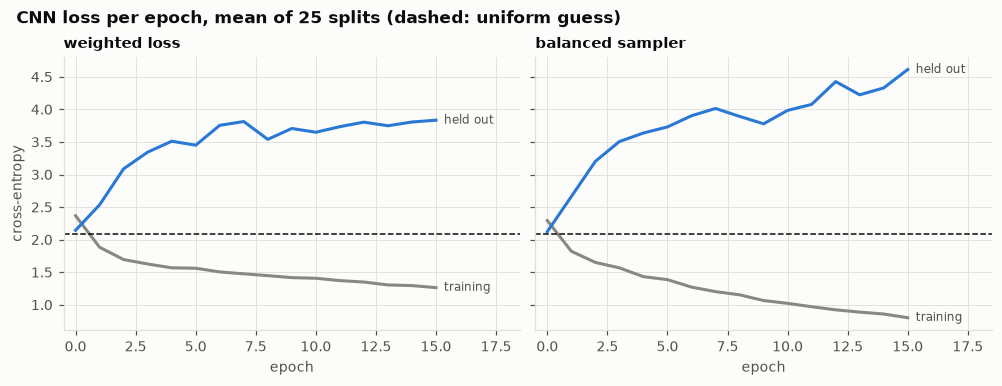

                        train_loss  val_balanced_ce
tag              epoch                             
balanced_sampler 0           2.293            2.123
                 1           1.822            2.662
                 5           1.386            3.731
                 15          0.801            4.612
weighted_loss    0           2.367            2.144
                 1           1.883            2.534
                 5           1.561            3.450
                 15          1.263            3.834


In [6]:
hist = pd.read_csv(RESULTS / "cnn_histories.csv")
hist = hist[hist["tag"].isin(["weighted_loss", "balanced_sampler"]) & (hist["epoch"] < 16)]
assert (hist.groupby(["tag", "epoch"]).size() == 25).all()
curve = hist.groupby(["tag", "epoch"])[["train_loss", "val_balanced_ce"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), constrained_layout=True, sharey=True)
for ax, tag in zip(axes, ["weighted_loss", "balanced_sampler"]):
    c = curve.loc[tag]
    ax.plot(c.index, c["train_loss"], color=viz.GREY, label="training clips")
    ax.plot(c.index, c["val_balanced_ce"], color=viz.BLUE, label="held-out babies")
    ax.axhline(np.log(8), color=viz.INK, lw=1, ls="--")
    ax.set(title=tag.replace("_", " "), xlabel="epoch")
    ax.text(c.index[-1], c["train_loss"].iloc[-1], "  training", color=viz.INK_2, va="center", fontsize=8)
    ax.text(c.index[-1], c["val_balanced_ce"].iloc[-1], "  held out", color=viz.INK_2, va="center", fontsize=8)
    ax.set_xlim(-0.5, 18.5)
axes[0].set_ylabel("cross-entropy")
fig.suptitle("CNN loss per epoch, mean of 25 splits (dashed: uniform guess)", x=0.01, ha="left", fontweight="bold")
plt.show()
print(curve.loc[(slice(None), [0, 1, 5, 15]), :].round(3).to_string())

## 5. Sensitivity: without source d6cda191

Notebook 06 found one source with 15 clips under 6 labels, 2 sexes and 3 age codes, behind 7 of the 12 most
confident mistakes. It was kept in every analysis: removing it *because* models fail on it would be choosing
data after seeing results. Here the existing predictions are simply re-scored without its 15 clips. The
models were still trained with it, so this asks only whether the conclusions depend on scoring it.

In [7]:
odd = idx["source"].str.startswith("d6cda191").to_numpy()
print(f"source d6cda191: {odd.sum()} clips, labels {idx.loc[odd, 'label'].value_counts().to_dict()}")
sens = pd.DataFrame([{"model": m, "variant": v, **{k: r[k] for k in ["balanced_accuracy", "vs_majority", "vs_majority_low", "vs_majority_high"]}}
                     for (fam, m, v, f) in MODELS[2:] for r in [score(pred[f], mask=~odd)]])
sens.insert(2, "BA, all clips", table["balanced_accuracy"].to_numpy()[2:])
sens = sens.rename(columns={"balanced_accuracy": "BA without d6cda191"})
sens["vs majority without (95% CI)"] = (sens["vs_majority"].map("{:+.3f}".format) + " (" +
                                        sens["vs_majority_low"].map("{:+.3f}".format) + ", " +
                                        sens["vs_majority_high"].map("{:+.3f}".format) + ")")
sens[["model", "variant", "BA, all clips", "BA without d6cda191", "vs majority without (95% CI)"]].round(3)

source d6cda191: 15 clips, labels {'hungry': 4, 'belly_pain': 3, 'tired': 3, 'discomfort': 2, 'scared': 2, 'cold_hot': 1}


,model,variant,"BA, all clips",BA without d6cda191,vs majority without (95% CI)
0,logistic_regression,argmax,0.125,0.126,"+0.004 (-0.017, +0.038)"
1,logistic_regression,prior_corrected,0.103,0.106,"-0.017 (-0.043, +0.015)"
2,knn,argmax,0.126,0.126,"+0.001 (-0.003, +0.008)"
3,knn,prior_corrected,0.108,0.109,"-0.016 (-0.037, +0.007)"
4,svm_rbf,argmax,0.125,0.125,"-0.000 (-0.001, +0.000)"
5,svm_rbf,prior_corrected,0.128,0.131,"+0.006 (-0.008, +0.024)"
6,random_forest,argmax,0.131,0.132,"+0.007 (-0.002, +0.017)"
7,random_forest,prior_corrected,0.112,0.110,"-0.016 (-0.046, +0.015)"
8,hist_gradient_boosting,argmax,0.126,0.126,"+0.001 (-0.002, +0.006)"
9,hist_gradient_boosting,prior_corrected,0.116,0.118,"-0.007 (-0.018, +0.007)"


## 6. What can be claimed

**What the numbers support**

- **No model recognises the eight states on babies it has not heard.** Under the grouped protocol, all 10
  classical variants and both CNNs score balanced accuracy 0.103-0.150 against 0.125 for always answering
  *hungry*, and every paired interval against that baseline includes 0. The best two are the CNN with weighted
  loss, 0.150 (95% CI 0.113-0.206), +0.026 (-0.012, +0.073), and the random forest, 0.131 (0.123-0.152),
  +0.006 (-0.002, +0.016). The CNN vs random forest difference is +0.020 (-0.020, +0.065).
- **The protocol is what makes this visible.** With ordinary clip-level folds, an untuned logistic regression
  scored 0.271 in notebook 04. Grouping by baby removes that, because babies differ more than classes do (notebook 02).
- **The probabilities carry no usable information either.** No model's log-loss is below the prior's 0.887, and no
  top-3 accuracy is above the baseline's 0.900.
- **More machinery made things worse, not better.** The prior-corrected decision rule lowered balanced accuracy in 4
  of 5 classical models. Against the random forest, logistic regression with it is -0.027 (-0.048, -0.000) and gradient
  boosting with it -0.015 (-0.028, -0.001). The CNN's validation loss rose from its first epoch on (2.144 → 3.834 with
  weighted loss, 2.123 → 4.612 with the sampler) while its training loss fell. It learnt the training babies, not the states.
- **The one class with apparent signal is confounded with the recording format.** Only *lonely* is ranked above chance:
  one-vs-rest AUROC 0.60 (random forest), 0.69 and 0.75 (CNNs), and CNN recall 0.400 and 0.545. But every *lonely* clip is a
  44.1 kHz recording, and the CNNs also predict *lonely* for the six 44.1 kHz clips of other classes more often than for
  8 kHz clips: 0.367 vs 0.122 (weighted loss) and 0.333 vs 0.247 (sampler). With this data the *lonely* signal cannot be
  told apart from the format, so it is not evidence that lonely cries are recognisable.
- **The conclusion does not hinge on one odd source.** Without the 15 clips of source d6cda191, every model's balanced
  accuracy moves by at most 0.003, and no interval against the baseline excludes 0.

**What the numbers do not support:** that cries carry no information about a baby's state. They show that *this*
dataset cannot demonstrate it: 382 of 479 clips are *hungry*, the other seven classes come from 3 to 17 babies each, the
labels are parents' guesses, and three classes are tied to one recording format.

**Limitations**

- **Labels.** They are what a parent entered in an app, never checked. 31 of 226 sources carry more than one label and
  19 more than one sex or age code, so some "babies" are probably shared or test installs.
- **Size.** *cold_hot* and *scared* have 3 and 4 babies, so no per-class number for them is reliable. Per-class results
  for the others rest on 7 to 17 babies.
- **Recording confound.** The format separates whole classes, and band-limiting the features did not remove its trace
  (notebook 06). All audio is 8 kHz, so nothing above 4 kHz is available to any model.
- **One dataset, one protocol.** There is no external test set. The 12 variants were all reported, but the "best" of
  them is still picked on the same splits that score it.
- **Reproducibility.** The classical models are seeded and reproduce exactly. The CNN ran on a GPU, which is not
  bit-for-bit reproducible, so its spread over repeats (± 0.013 and ± 0.030) is the measure of run-to-run variation.

**What data would help:** tens of babies per state rather than 3 to 17; every state recorded on the same devices and in the same
format; labels confirmed by what settled the baby (fed, burped, changed) or by a second observer; and several states from
each baby, so models could compare a baby with itself.

### Model card

| | |
|---|---|
| **Models** | Five classical families with two decision rules each (notebook 05, `src/models.py`) and a small log-mel CNN with two imbalance treatments (notebook 07, `src/cnn.py`). None is recommended for use. |
| **Data** | The Donate-a-Cry recordings (notebook 01): 479 clips after removing 24 generated copies and 9 mislabelled files, from 226 sources, 8 parent-reported states; 382 clips are *hungry*. Audio at 8 kHz mono, about 7 s. |
| **Evaluation** | 5-fold cross-validation grouped by baby and stratified by label, repeated with 5 seeds (25 splits, `metadata/folds.csv`). Tuning and early stopping use only the training part of each split. Primary metrics: balanced accuracy and macro-F1, with cluster-bootstrap intervals over babies. |
| **Performance** | Best balanced accuracy 0.150 (CNN) and 0.131 (random forest) against 0.125 for always answering *hungry*. No difference from that baseline is distinguishable (table above). |
| **Intended use** | Research and teaching: an example of evaluating a small, imbalanced, confounded audio dataset without leakage. |
| **Not for** | Telling a parent or carer why a baby is crying, or any decision about a baby's care or health. On new babies these models are no better than always saying *hungry*. |
| **Known risks** | A confident wrong answer could delay attention to a real need. The *lonely* predictions partly follow the recording format, not the cry. |